# Q2 : Délai de réservation
Anaëlle Tuebou Kamga


In [1]:
import pandas as pd
df = pd.read_csv("../data/clean/valmont_clean.csv")
print("Réservations :", len(df))
df = df[df["flag_anomalie"] == 0].copy()
print("Réservations analysées :", len(df))

Réservations : 800
Réservations analysées : 794


In [2]:
print("Valeurs manquantes :", df[["delai_reservation_j", "a_annule"]].isna().sum().sum())
print("Valeurs de a_annule :", sorted(df["a_annule"].unique()))
print("Délai min et max :", df["delai_reservation_j"].min(), "-", df["delai_reservation_j"].max())
print("Taux d'annulation global :", round(df["a_annule"].mean() * 100, 1), "%")
print("Délai moyen :", round(df["delai_reservation_j"].mean(), 1), "| médian :", df["delai_reservation_j"].median())

Valeurs manquantes : 0
Valeurs de a_annule : [np.int64(0), np.int64(1)]
Délai min et max : 0 - 235
Taux d'annulation global : 26.1 %
Délai moyen : 42.2 | médian : 28.0


In [3]:
df["tranche_delai"] = pd.qcut(df["delai_reservation_j"], q=5)
par_tranche = df.groupby("tranche_delai", observed=True)["a_annule"].agg(["size", "mean"])
par_tranche.columns = ["reservations", "taux_annulation"]
par_tranche["taux_annulation"] = (par_tranche["taux_annulation"] * 100).round(1)
par_tranche


,reservations,taux_annulation
tranche_delai,,
"(-0.001, 8.0]",165,15.2
"(8.0, 19.0]",161,17.4
"(19.0, 41.0]",153,24.8
"(41.0, 73.4]",156,30.1
"(73.4, 235.0]",159,43.4


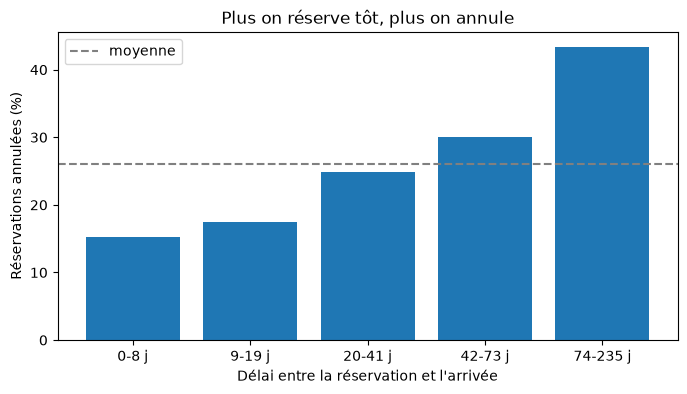

In [4]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4))
etiquettes = ["0-8 j", "9-19 j", "20-41 j", "42-73 j", "74-235 j"]
ax.bar(etiquettes, par_tranche["taux_annulation"])
ax.axhline(df["a_annule"].mean() * 100, color="grey", linestyle="--", label="moyenne")
ax.set_ylabel("Réservations annulées (%)")
ax.set_xlabel("Délai entre la réservation et l'arrivée")
ax.set_title("Plus on réserve tôt, plus on annule")
ax.legend()
plt.show()

In [5]:
from scipy.stats import chi2_contingency
tableau = pd.crosstab(df["tranche_delai"], df["a_annule"])
chi2, p_valeur, ddl, attendus = chi2_contingency(tableau)
print("Khi-deux =", round(chi2, 1), "| ddl =", ddl, "| p-valeur =", f"{p_valeur:.1e}")
print("Plus petit effectif attendu :", round(attendus.min(), 1))


Khi-deux = 42.7 | ddl = 4 | p-valeur = 1.2e-08
Plus petit effectif attendu : 39.9


In [6]:
from scipy.stats import mannwhitneyu
delai_annulees = df.loc[df["a_annule"] == 1, "delai_reservation_j"]
delai_honorees = df.loc[df["a_annule"] == 0, "delai_reservation_j"]
stat, p_mw = mannwhitneyu(delai_annulees, delai_honorees)
print("Délai médian des annulées :", delai_annulees.median(), "jours")
print("Délai médian des honorées :", delai_honorees.median(), "jours")
print("p-valeur de Mann-Whitney :", f"{p_mw:.1e}")

Délai médian des annulées : 52.0 jours
Délai médian des honorées : 22.0 jours
p-valeur de Mann-Whitney : 1.1e-10


**Lecture** : le taux d'annulation monte régulièrement avec le délai, de 15 % pour les réservations faites 8 jours ou moins avant l'arrivée à 43 % au-delà de 73 jours. Le khi-deux et Mann-Whitney rejettent tous les deux l'absence de lien (p-valeurs très inférieures à 5 %). Les annulées ont été réservées en médiane plus de deux fois plus tôt que les honorées.

Mais ce constat peut venir du segment : il faut vérifier à segment égal.

## Le segment explique-t-il tout ?

In [7]:
print(df.groupby("segment_declare")["delai_reservation_j"].median())
pd.crosstab(df["tranche_delai"], df["segment_declare"])


segment_declare
affaires     9.0
groupe      54.5
loisir      56.0
Name: delai_reservation_j, dtype: float64


segment_declare,affaires,groupe,loisir
tranche_delai,,,
"(-0.001, 8.0]",152,1,12
"(8.0, 19.0]",116,22,23
"(19.0, 41.0]",48,32,73
"(41.0, 73.4]",2,50,104
"(73.4, 235.0]",0,45,114


In [8]:
taux_segment = pd.crosstab(df["tranche_delai"], df["segment_declare"],
                           values=df["a_annule"], aggfunc="mean") * 100
taux_segment.round(1)

segment_declare,affaires,groupe,loisir
tranche_delai,,,
"(-0.001, 8.0]",15.8,0.0,8.3
"(8.0, 19.0]",12.9,27.3,30.4
"(19.0, 41.0]",27.1,18.8,26.0
"(41.0, 73.4]",0.0,36.0,27.9
"(73.4, 235.0]",NaN,44.4,43.0


**Lecture** : les clients affaires réservent presque tous à moins de 20 jours, les clients loisir et groupe beaucoup plus tôt. Le segment et le délai sont donc mélangés. Pourtant, à l'intérieur du segment loisir, le seul présent en nombre sur toutes les tranches, le taux d'annulation monte aussi avec le délai, de 8 % à 43 %. La régression logistique permet de mesurer cela proprement.

In [9]:
import numpy as np
import statsmodels.formula.api as smf
df["delai_30j"] = df["delai_reservation_j"] / 30
modele_1 = smf.logit("a_annule ~ delai_30j", data=df).fit(disp=0)
modele_2 = smf.logit("a_annule ~ delai_30j + C(segment_declare)", data=df).fit(disp=0)
print("Délai seul : x", round(np.exp(modele_1.params["delai_30j"]), 2))
print("Délai + segment : x", round(np.exp(modele_2.params["delai_30j"]), 2))
print("p-valeur :", f"{modele_2.pvalues['delai_30j']:.1e}")

Délai seul : x 1.5
Délai + segment : x 1.42
p-valeur : 2.0e-06


modele_3 = smf.logit("a_annule ~ delai_30j + C(segment_declare) + C(canal) + C(categorie)"
                     " + C(saison) + weekend + nb_nuits + nb_personnes", data=df).fit(disp=0)
ic = np.exp(modele_3.conf_int().loc["delai_30j"])
print("Toutes les variables : x", round(np.exp(modele_3.params["delai_30j"]), 2))
print("Intervalle de confiance à 95 % :", round(ic[0], 2), "à", round(ic[1], 2))

**Lecture** : chaque mois de délai en plus multiplie les chances d'annuler par environ 1,4. Ce chiffre ne bouge presque pas quand on ajoute le segment (1,42), puis toutes les autres variables connues à la réservation (1,43, intervalle de confiance à 95 % de 1,24 à 1,65, entièrement au-dessus de 1). L'effet du délai ne vient donc pas du segment.

In [12]:
## Réponse, décision et gain

In [13]:
tot = df["delai_reservation_j"] > 60
annul_tot = tot & (df["a_annule"] == 1)
print("Taux d'annulation au-delà de 60 jours :", round(df.loc[tot, "a_annule"].mean() * 100, 1), "%")
print("Taux d'annulation à 60 jours ou moins :", round(df.loc[~tot, "a_annule"].mean() * 100, 1), "%")
ca_perdu = (df.loc[annul_tot, "nb_nuits"] * df.loc[annul_tot, "prix_nuit_eur"]).sum()
print("Chiffre d'affaires perdu par mois :", round(ca_perdu / 12), "€")
print("Gain avec un acompte de 30 % :", round(ca_perdu / 12 * 0.30), "€ par mois")

Taux d'annulation au-delà de 60 jours : 39.6 %
Taux d'annulation à 60 jours ou moins : 21.0 %
Chiffre d'affaires perdu par mois : 4038 €
Gain avec un acompte de 30 % : 1211 € par mois


### Réponse à la direction

**Chiffre** : c'est l'inverse de l'intuition. Les réservations faites 8 jours ou moins avant l'arrivée sont annulées à 15 %, celles faites plus de 73 jours avant à 43 %. Chaque mois de délai en plus multiplie les chances d'annulation par 1,4, à segment égal.

**Pourquoi c'est solide** : khi-deux et Mann-Whitney significatifs, effet du délai stable dans trois régressions logistiques, et visible à l'intérieur du segment loisir seul.

**Décision** : au-delà de 60 jours avant l'arrivée, proposer par défaut un tarif avec acompte non remboursable de 30 %, et garder le tarif flexible pour les réservations proches de la date.

**Gain** : au-delà de 60 jours, 40 % des réservations sont annulées contre 21 % en dessous, soit environ 4 000 € de chiffre d'affaires perdu par mois dans l'échantillon. Un acompte de 30 % en conserverait environ 1 200 € par mois. C'est une hypothèse prudente : si l'acompte décourage des annulations, le gain est plus élevé.

**Limite** : on ne connaît pas la date d'annulation. Une annulation faite 80 jours avant se revend facilement, c'est l'annulation tardive qui coûte.